<a href="https://colab.research.google.com/github/nadhirahayani/Analisis-Deret-Waktu/blob/main/tugas_kelompok_minggu_8_pendugaan_parameter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS KELOMPOK - PENDUGAAN PARAMETER**  
---


Anggota Kelompok 1:
1. Chindy Putri Army (M0501251024)
2. Fitri Hayati (M0501251043)
3. Nadhira Maulida Hayani (M0501261093

---

1\. Buatlah simulasi deret waktu (parameter yang digunakan bebas, tetapi berbeda dengan contoh yag sudah digunakan di atas) menggunakan seed 25xx, dimana xx adalah jumlah dua digit terakhir NIM anggota kelompok (misal NIM: 09 dan 28, maka seed yang digunakan 2537 . Lakukan pendugaan parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum. Kelompok 1: ARIMA (0,0,1) dan ARIMA (2,2,2)


In [ ]:
%load_ext rpy2.ipython

###**Dibangkitkan 120 Data Simulasi dari Model ARIMA(0,0,1) dengan Parameter $\theta=-0.25$**

In [ ]:
%%R
set.seed(2560)
ma1=arima.sim(list(order = c(0,0,1), ma = -0.25), n = 120)
summary(ma1)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.81020 -0.73064 -0.10983 -0.02087  0.69666  2.86297 


###**Pendugaan Parameter Model ARIMA(0,0,1) dengan metode CSS**

In [ ]:
%%R
print(arima(ma1, order=c(0,0,1), method='CSS'))


Call:
arima(x = ma1, order = c(0, 0, 1), method = "CSS")

Coefficients:
          ma1  intercept
      -0.2492    -0.0175
s.e.   0.0966     0.0745

sigma^2 estimated as 1.174:  part log likelihood = -179.91


Berdasarkan hasil pendugaan menggunakan metode CSS pada model ARIMA(0,0,1), diperoleh koefisien MA(1) sebesar $\hat\theta_{CSS}=-0.2492$, sedangkan parameter sebenarnya yaitu $\theta=-0,25$. Selisih pendugaan sebesar $0,0008$ menunjukkan bahwa hasil estimasi cukup akurat pada simulasi ini. Selain itu, diperoleh nilai intercept sebesar $-0,0175$ dan varians galat sebesar $1,174$. Hasil ini menunjukkan bahwa metode CSS mampu menduga koefisien MA(1) dengan baik pada satu kali simulasi.

###**Pendugaan Parameter Model ARIMA (0,0,1) dengan Metode MLE**

In [ ]:
%%R
print(arima(ma1, order=c(0,0,1),method='ML'))


Call:
arima(x = ma1, order = c(0, 0, 1), method = "ML")

Coefficients:
          ma1  intercept
      -0.2529    -0.0182
s.e.   0.0976     0.0741

sigma^2 estimated as 1.173:  log likelihood = -179.86,  aic = 365.73


Berdasarkan hasil pendugaan menggunakan metode MLE pada model ARIMA(0,0,1), diperoleh $\hat\theta_{MLE}=-0.2529$, sedangkan parameter sebenarnya yaitu $\theta=-0,25$. Selisih pendugaan sebesar $-0,0029$ menunjukkan bahwa hasil estimasi cukup akurat pada simulasi ini. Nilai intercept yang diperoleh sebesar $-0,0182$ dengan varians galat sebesar $1,173$. Hasil ini menunjukkan bahwa metode MLE mampu menduga koefisien MA(1) dengan baik.


###**Dibangkitkan 120 data simulasi dari Model ARIMA(2,2,2) dengan parameter $\phi_1=0.1, \phi_2=0.5, \theta_1=0.2,$ dan $\theta_2=0.25$**

In [ ]:
%%R
set.seed(2560)
# Simulasi ARMA(2,2)
arma22 <- arima.sim(
  model = list(
    order = c(2, 0, 2),
    ar = c(0.1, 0.5),
    ma = c(0.2, 0.25)
  ),
  n = 120
)
# Integrasi dua kali menjadi ARIMA(2,2,2)
arima222 <- cumsum(cumsum(arma22))
head(arima222)

[1]  2.695854  4.820769  7.767626  9.909146 12.242657 13.652407


###**Pendugaan Parameter Model ARIMA(2,2,2) dengan Metode CSS.**

In [ ]:
%%R
print(arima(arima222, order=c(2,2,2),method='CSS'))


Call:
arima(x = arima222, order = c(2, 2, 2), method = "CSS")

Coefficients:
         ar1     ar2     ma1     ma2
      0.0504  0.3718  0.3346  0.6263
s.e.  0.1054  0.1062  0.0878  0.0907

sigma^2 estimated as 0.9412:  part log likelihood = -163.86


Berdasarkan hasil pendugaan menggunakan metode CSS pada model ARIMA(2,2,2), diperoleh koefisien AR(1) sebesar $\hat{\phi}_1=0,0504$, AR(2) sebesar $\hat{\phi}_2=0,3718$, MA(1) sebesar $\hat{\theta}_1=0,3346$, dan MA(2) sebesar $\hat{\theta}_2=0,6263$. Selisih antara setiap penduga dan parameter sebenarnya dihitung sebagai berikut:
$$
\begin{aligned}
\hat{\phi}_1-\phi_1 &= 0{,}0504-0{,}1=-0{,}0496,\\
\hat{\phi}_2-\phi_2 &= 0{,}3718-0{,}5=-0{,}1282,\\
\hat{\theta}_1-\theta_1 &= 0{,}3346-0{,}2=0{,}1346,\\
\hat{\theta}_2-\theta_2 &= 0{,}6263-0{,}25=0{,}3763.
\end{aligned}
$$

Selain itu, diperoleh estimasi varians galat sebesar $0,9412$. Hasil tersebut menunjukkan bahwa pendugaan parameter pada satu simulasi masih memiliki selisih terhadap parameter sebenarnya, terutama pada koefisien MA(2).


###**Pendugaan Parameter Model ARIMA(2,2,2) dengan Metode MLE**

In [ ]:
%%R
print(arima(arima222, order=c(2,2,2),method='ML'))


Call:
arima(x = arima222, order = c(2, 2, 2), method = "ML")

Coefficients:
         ar1     ar2     ma1     ma2
      0.0491  0.3665  0.3259  0.6163
s.e.  0.1071  0.1075  0.0910  0.0932

sigma^2 estimated as 0.9344:  log likelihood = -164.47,  aic = 338.93


Berdasarkan hasil pendugaan menggunakan metode MLE pada model ARIMA(2,2,2), diperoleh koefisien AR(1) sebesar $\hat{\phi}_1=0,0491$, AR(2) sebesar $\hat{\phi}_2=0,3665$, MA(1) sebesar $\hat{\theta}_1=0,3259$, dan MA(2) sebesar $\hat{\theta}_2=0,6163$. Selisih antara setiap penduga dan parameter sebenarnya dihitung sebagai berikut:
$$
\begin{aligned}
\hat{\phi}_1-\phi_1 &= 0{,}0491-0{,}1=-0{,}0509,\\
\hat{\phi}_2-\phi_2 &= 0{,}3665-0{,}5=-0{,}1335,\\
\hat{\theta}_1-\theta_1 &= 0{,}3259-0{,}2=0{,}1259,\\
\hat{\theta}_2-\theta_2 &= 0{,}6163-0{,}25=0{,}3663.
\end{aligned}
$$

Selain itu, diperoleh estimasi varians galat sebesar $0,9547$, dengan nilai AIC sebesar $347,11$. Hasil tersebut menunjukkan bahwa pendugaan parameter pada satu simulasi masih memiliki selisih terhadap parameter sebenarnya, terutama pada koefisien MA(2).


###**Perbandingan Hasil Pendugaan Parameter Model ARIMA(2,2,2) Menggunakan Metode CSS dan MLE**

In [ ]:
%%R
# 1. Jalankan estimasi model
fit_css <- arima(arima222, order = c(2, 2, 2), method = "CSS")
fit_ml  <- arima(arima222, order = c(2, 2, 2), method = "ML")

# 2. Buat tabel perbandingan dengan Nilai Asli
tabel_perbandingan <- data.frame(
  Parameter = c("AR1", "AR2", "MA1", "MA2"),
  Nilai_Asli = c(0.1, 0.5, 0.2, 0.25),
  Penduga_OLS_CSS = coef(fit_css)[1:4],
  Penduga_MLE = coef(fit_ml)[1:4]
)

# 3. Tampilkan tabel tanpa nama baris
print(tabel_perbandingan, row.names = FALSE)

 Parameter Nilai_Asli Penduga_OLS_CSS Penduga_MLE
       AR1       0.10      0.05035487  0.04905444
       AR2       0.50      0.37180852  0.36651275
       MA1       0.20      0.33458779  0.32590136
       MA2       0.25      0.62625328  0.61629420


Berdasarkan tabel perbandingan di atas, metode CSS dan MLE menghasilkan pendugaan parameter yang relatif berdekatan. Metode CSS memberikan hasil yang lebih dekat dengan parameter sebenarnya pada AR(1) dan AR(2), sedangkan MLE lebih dekat pada MA(1) dan MA(2). Namun, hasil ini baru didasarkan pada satu simulasi sehingga diperlukan 30 kali pengulangan untuk membandingkan kinerja kedua metode berdasarkan bias dan ragam penduga.

---

 2\. Ulangi langkah no.1 sebanyak 30 ulangan. Hitunglah bias dan ragam dari penduga parameter menggunakan metode Kuadrat Terkecil dan Kemungkinan Maksimum yang diperoleh dari 30 ulangan tersebut. Dan buatlah boxplot untuk memvisualisasikan bias dan ragam tersebut. Interpretasikan boxpot yang diperoleh

###**Dibangkitkan 120 data simulasi dari Model ARIMA(0,0,1) dengan parameter  $\theta=-0.25$ sebanyak 30 kali. Selanjutnya dilakukan pendugaan parameter menggunakan OLS dan MLE.**

TABEL HASIL PENDUGAAN 30 KALI SIMULASI
   Ulangan         CSS         MLE
1        1 -0.27143262 -0.27053502
2        2 -0.34902243 -0.34700893
3        3 -0.34400457 -0.34811206
4        4 -0.23091851 -0.22978973
5        5 -0.32785523 -0.32555039
6        6 -0.16945054 -0.16858437
7        7 -0.23869165 -0.23660915
8        8 -0.16036377 -0.16018494
9        9 -0.27471093 -0.27789972
10      10 -0.07307163 -0.07313449
11      11 -0.18257474 -0.18402431
12      12 -0.16367478 -0.16236590
13      13 -0.43311746 -0.43999665
14      14  0.05371616  0.05490924
15      15 -0.37857103 -0.39248050
16      16 -0.12635264 -0.13096878
17      17 -0.14038095 -0.14069340
18      18 -0.34893517 -0.35583632
19      19 -0.14795663 -0.14780495
20      20 -0.20973743 -0.20772951
21      21 -0.30684096 -0.30843227
22      22 -0.18524359 -0.19156395
23      23 -0.15313152 -0.15220945
24      24 -0.28647103 -0.28483453
25      25 -0.27259367 -0.27203891
26      26 -0.51892896 -0.51430941
27      27 -0.30

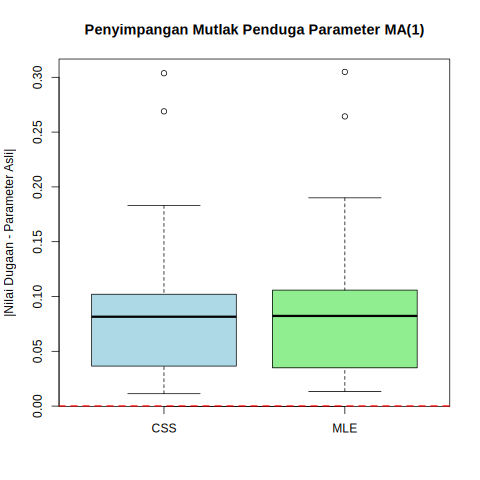

In [ ]:
%%R

# 1. MENENTUKAN PARAMETER SIMULASI
B <- 30
n <- 120
theta_asli <- -0.25

# Menyediakan tempat menyimpan hasil pendugaan
est_css <- numeric(B)
est_mle <- numeric(B)

# 2. SIMULASI DAN PENDUGAAN PARAMETER
for (i in 1:B) {

  # A. Membangkitkan data ARIMA(0,0,1)
  data_sim <- arima.sim(
    model = list(
      order = c(0, 0, 1),
      ma = theta_asli
    ),
    n = n)

  # B. Pendugaan dengan Conditional Sum of Squares (CSS)
  fit_css <- arima(
    data_sim,
    order = c(0, 0, 1),
    include.mean = FALSE,
    method = "CSS")

  # C. Pendugaan dengan Maximum Likelihood (MLE)
  fit_mle <- arima(
    data_sim,
    order = c(0, 0, 1),
    include.mean = FALSE,
    method = "ML")

  # D. Menyimpan penduga parameter MA(1)
  est_css[i] <- unname(fit_css$coef["ma1"])
  est_mle[i] <- unname(fit_mle$coef["ma1"])
}

# 3. MENAMPILKAN HASIL 30 KALI PENDUGAAN
hasil_estimasi <- data.frame(
  Ulangan = 1:B,
  CSS = est_css,
  MLE = est_mle)

cat("TABEL HASIL PENDUGAAN 30 KALI SIMULASI\n")
print(hasil_estimasi)

# 4. MENGHITUNG BIAS DAN RAGAM PENDUGA
bias_css <- mean(est_css) - theta_asli
bias_mle <- mean(est_mle) - theta_asli

ragam_css <- var(est_css)
ragam_mle <- var(est_mle)

ringkasan <- data.frame(
  Metode = c("CSS", "MLE"),
  Parameter_Asli = rep(theta_asli, 2),
  Rata_rata_Penduga = c(mean(est_css), mean(est_mle)),
  Bias = c(bias_css, bias_mle),
  Ragam = c(ragam_css, ragam_mle),
  MSE = c(
    mean((est_css - theta_asli)^2),
    mean((est_mle - theta_asli)^2)
  )
)

cat("\nTABEL BIAS DAN RAGAM PENDUGA\n")
print(ringkasan, row.names = FALSE, digits = 5)

# 5. BOXPLOT NILAI PENDUGA PARAMETER
boxplot(
  est_css, est_mle,
  names = c("CSS", "MLE"),
  main = "Boxplot Penduga Parameter MA(1)",
  xlab = "Metode Pendugaan",
  ylab = "Nilai Penduga MA(1)",
  col = c("lightblue", "lightgreen"))

# Garis merah = parameter sebenarnya
abline(h = theta_asli,col = "red",lty = 2,lwd = 2)
legend("topright", legend = "Parameter sebenarnya (-0.25)",
       col = "red", lty = 2, lwd = 2,bty = "n")

# 6. BOXPLOT PENYIMPANGAN MUTLAK
dev_css <- abs(est_css - theta_asli)
dev_mle <- abs(est_mle - theta_asli)

boxplot(
  dev_css, dev_mle,
  names = c("CSS", "MLE"),
  main = "Penyimpangan Mutlak Penduga Parameter MA(1)",
  ylab = "|Nilai Dugaan - Parameter Asli|",
  col = c("lightblue", "lightgreen")
)

# Penyimpangan mutlak ideal adalah nol
abline(h = 0,col = "red",lty = 2,lwd = 2)

Berdasarkan hasil 30 kali simulasi pada model ARIMA(0,0,1), metode CSS menghasilkan bias rata-rata sebesar $0{,}0078042$ dan ragam sebesar $0{,}012962$, sedangkan metode MLE menghasilkan bias rata-rata sebesar $0{,}0068084$ dan ragam sebesar $0{,}013154$. Hasil tersebut menunjukkan bahwa MLE memiliki bias rata-rata yang sedikit lebih dekat ke nol, sedangkan CSS memiliki ragam yang sedikit lebih kecil. Boxplot juga memperlihatkan median dan sebaran penyimpangan mutlak yang relatif serupa pada kedua metode. Dengan demikian, MLE menghasilkan rata-rata pendugaan yang sedikit lebih dekat dengan parameter sebenarnya, yaitu $\theta = -0{,}25$, sedangkan CSS menunjukkan variasi pendugaan yang sedikit lebih kecil. Secara keseluruhan, kinerja kedua metode relatif sebanding pada simulasi ini.

###**Dibangkitkan 120 data simulasi dari deret ARIMA(2,2,2) dengan parameter  $\phi_1=0.1, \phi_2=0.5, \theta_1=0.2,$ dan $\theta_2=0.25$ sebanyak 30 kali. Selanjutnya dilakukan pendugaan parameter menggunakan OLS dan MLE.**


TABEL HASIL PENDUGAAN PARAMETER
 Parameter Ulangan Parameter_Asli Penduga_CSS Penduga_MLE
       ar1       1           0.10   0.3733146  0.39662225
       ar1       2           0.10  -0.0686215 -0.06586732
       ar1       3           0.10   0.5657333  0.66330587
       ar1       4           0.10   0.0933179  0.09320581
       ar1       5           0.10   0.0458056  0.03643599
       ar1       6           0.10   0.0914358  0.09481495
       ar1       7           0.10   0.1742480  0.17587803
       ar1       8           0.10   0.2363440  0.23302979
       ar1       9           0.10  -0.0320063 -0.05556945
       ar1      10           0.10   0.0930792  0.02252425
       ar1      11           0.10   0.0313657  0.04624374
       ar1      12           0.10   0.1859049  0.18567143
       ar1      13           0.10  -0.1629620 -0.15038446
       ar1      14           0.10  -0.0274824 -0.01775449
       ar1      15           0.10   0.1109701  0.10076544
       ar1      16           0.10   0.1

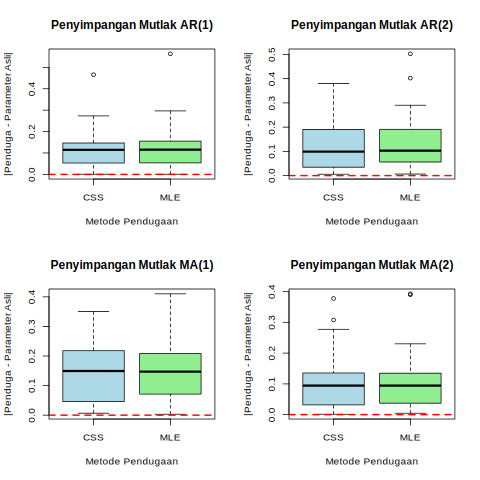

In [ ]:
%%R

# 1. MENENTUKAN DESAIN SIMULASI
n_rep <- 30
n_obs <- 120

# Parameter sebenarnya
param_asli <- c(ar1 = 0.1, ar2 = 0.5, ma1 = 0.2, ma2 = 0.25)
nama_param <- names(param_asli)

# Menyediakan matriks untuk menyimpan hasil pendugaan
est_css <- matrix(
  NA_real_, nrow = n_rep, ncol = 4,
  dimnames = list(NULL, nama_param))

est_mle <- matrix(
  NA_real_, nrow = n_rep, ncol = 4,
  dimnames = list(NULL, nama_param))

# 2. SIMULASI DAN PENDUGAAN PARAMETER 30 KALI
for (i in 1:n_rep) {

  # A. Membangkitkan data ARIMA(2,2,2)
  data_sim <- arima.sim(
    model = list(
      order = c(2, 2, 2),
      ar = c(0.1, 0.5),
      ma = c(0.2, 0.25)
    ),
    n = n_obs)

  # B. Pendugaan dengan CSS
  fit_css <- tryCatch(
    arima(
      data_sim,
      order = c(2, 2, 2),
      include.mean = FALSE,
      method = "CSS"),
    error = function(e) NULL)

  # C. Pendugaan dengan MLE
  fit_mle <- tryCatch(
    arima(
      data_sim,
      order = c(2, 2, 2),
      include.mean = FALSE,
      method = "ML"),
    error = function(e) NULL)

  # D. Menyimpan koefisien berdasarkan nama parameter
  if (!is.null(fit_css)) {
    koef <- fit_css$coef
    if (all(nama_param %in% names(koef))) {
      est_css[i, ] <- koef[nama_param]
    }
  }

  if (!is.null(fit_mle)) {
    koef <- fit_mle$coef
    if (all(nama_param %in% names(koef))) {
      est_mle[i, ] <- koef[nama_param]
    }
  }
}

# 3. TABEL HASIL PENDUGAAN 30 KALI SIMULASI
tabel_estimasi <- data.frame(
  Ulangan = 1:n_rep,
  Parameter_Asli = rep(param_asli, each = n_rep),
  Parameter = rep(nama_param, each = n_rep),
  CSS = as.vector(est_css),
  MLE = as.vector(est_mle))

# Membentuk tabel dengan satu baris per pengulangan-parameter
tabel_estimasi <- do.call(
  rbind,
  lapply(nama_param, function(p) {
    data.frame(
      Parameter = p,
      Ulangan = 1:n_rep,
      Parameter_Asli = unname(param_asli[p]),
      Penduga_CSS = est_css[, p],
      Penduga_MLE = est_mle[, p])}))

rownames(tabel_estimasi) <- NULL

cat("\nTABEL HASIL PENDUGAAN PARAMETER\n")
print(tabel_estimasi, row.names = FALSE, digits = 5)

# 4. MENGHITUNG BIAS DAN RAGAM PENDUGA
ringkasan <- do.call(rbind,lapply(nama_param, function(p) {
    x_css <- est_css[, p]
    x_mle <- est_mle[, p]

    data.frame(
      Parameter = p,
      Metode = c("CSS", "MLE"),
      Parameter_Asli = unname(param_asli[p]),
      Jumlah_Berhasil = c(
        sum(is.finite(x_css)),
        sum(is.finite(x_mle))),
      Rata_rata_Penduga = c(
        mean(x_css, na.rm = TRUE),
        mean(x_mle, na.rm = TRUE)),
      Bias = c(
        mean(x_css, na.rm = TRUE) - param_asli[p],
        mean(x_mle, na.rm = TRUE) - param_asli[p]),
      Ragam = c(
        var(x_css, na.rm = TRUE),
        var(x_mle, na.rm = TRUE)),
      MSE = c(
        mean((x_css - param_asli[p])^2, na.rm = TRUE),
        mean((x_mle - param_asli[p])^2, na.rm = TRUE)))}))

rownames(ringkasan) <- NULL

cat("\nTABEL BIAS DAN RAGAM PENDUGA\n")
print(ringkasan, row.names = FALSE, digits = 5)

# 5. BOXPLOT NILAI PENDUGA PARAMETER
par(mfrow = c(2, 2))

nama_label <- c(
  ar1 = "AR(1)",
  ar2 = "AR(2)",
  ma1 = "MA(1)",
  ma2 = "MA(2)")

for (p in nama_param) {
  boxplot(
    est_css[, p], est_mle[, p],
    names = c("CSS", "MLE"),
    main = paste("Penduga Parameter", nama_label[p]),
    xlab = "Metode Pendugaan",
    ylab = "Nilai Penduga",
    col = c("lightblue", "lightgreen"))

  # Garis merah menunjukkan parameter sebenarnya
  abline(h = param_asli[p], col = "red", lty = 2, lwd = 2)}

par(mfrow = c(1, 1))

# 6. BOXPLOT PENYIMPANGAN MUTLAK
dev_css <- abs(sweep(est_css, 2, param_asli, "-"))
dev_mle <- abs(sweep(est_mle, 2, param_asli, "-"))

par(mfrow = c(2, 2))

for (p in nama_param) {

  boxplot(
    dev_css[, p], dev_mle[, p],
    names = c("CSS", "MLE"),
    main = paste("Penyimpangan Mutlak", nama_label[p]),
    xlab = "Metode Pendugaan",
    ylab = "|Penduga - Parameter Asli|",
    col = c("lightblue", "lightgreen"))

  abline(h = 0, col = "red", lty = 2, lwd = 2)}

par(mfrow = c(1, 1))

Berdasarkan hasil 30 kali simulasi model ARIMA(2,2,2), metode CSS menghasilkan bias yang lebih dekat ke nol pada parameter AR(1), AR(2), dan MA(2), sedangkan MLE lebih dekat pada parameter MA(1). Dari sisi ragam, CSS memiliki ragam lebih kecil pada AR(1) dan MA(2), sementara MLE memiliki ragam lebih kecil pada MA(1) dan AR(2). Boxplot penyimpangan mutlak menunjukkan pola sebaran yang relatif serupa antara kedua metode, meskipun terdapat beberapa pencilan pada AR(1) dan AR(2). Secara keseluruhan, hasil ini menunjukkan bahwa tidak ada satu metode yang unggul untuk seluruh parameter; kinerja CSS dan MLE bergantung pada parameter yang diduga.